# 05 — Evaluasi Komparatif Terstandarisasi

Notebook ini memuat seluruh checkpoint, lalu menghitung pada **Test Set**:
* Test MSE / PSNR / SSIM untuk keluarga autoencoder;
* FID (Inception-v3, 2048-d) untuk sampel sintetis dari prior, dengan jumlah sampel yang sama untuk setiap model;
* cakupan mode (distribusi kelas sampel menurut MLP Classifier);
* training time per epoch dan inference latency per batch 64 (GPU fp32 dan CPU);
* Figur 1, 2, 4, dan 5 serta tabel komparasi Bagian IV.

In [1]:
# ===== Import library =====
import time
import numpy as np
import pandas as pd                  # untuk menampilkan tabel hasil
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt

from common import *
from models import *                 # semua arsitektur model

set_seed(SEED)
train_loader, val_loader, test_loader = get_loaders(BATCH_SIZE)
X_test, Y_test = test_loader.dataset.tensors   # seluruh gambar & label Test Set sebagai tensor
N_FID = 200 if QUICK else 2000                 # jumlah sampel per model untuk FID
LATENT, Z_DIM = 64, 100                        # dimensi laten AE/VAE dan noise GAN


def load(model, name):
    # Muat bobot dari checkpoints/<name>, pindahkan ke device, dan set mode evaluasi
    model.load_state_dict(torch.load(os.path.join(CKPT_DIR, name), map_location=DEVICE))
    return model.to(DEVICE).eval()


# Muat semua model terlatih dari notebook 01-04
ae = load(VanillaAE(LATENT), "vanilla_ae.pt")
sae = load(SparseAE(LATENT), "sparse_ae.pt")
vae = load(VAE(LATENT), "vae.pt")
G_gan = load(MLPGenerator(Z_DIM), "vanilla_gan_G.pt")
G_dc = load(DCGANGenerator(Z_DIM), "dcgan_G.pt")
# Konfigurasi U-Net dibaca dari file info agar arsitekturnya sama dengan saat training
unet_ema = load(UNet(**load_json("ddpm_sampling_info.json")["unet_cfg"]), "ddpm_unet_ema.pt")
ddpm = DDPM(unet_ema, T=1000).to(DEVICE).eval()
clf = load(MLPClassifier(), "mlp_classifier.pt")   # dipakai sebagai "juri" kelas untuk mode coverage
print("semua checkpoint dimuat")

semua checkpoint dimuat


## 1. Metrik rekonstruksi pada Test Set

In [2]:
# Fungsi rekonstruksi per model (VAE memakai mu tanpa noise -> deterministik)
recon_fns = {
    "Vanilla AE": lambda x: ae(x)[0],
    "Sparse AE": lambda x: sae(x)[0],
    "VAE": lambda x: vae.decode(vae.encode(x)[0]),
}
# Hitung MSE, PSNR, SSIM di Test Set
recon = {k: reconstruction_metrics(f, test_loader) for k, f in recon_fns.items()}
# Tampilkan sebagai tabel (baris = model)
pd.DataFrame(recon).T

,mse,psnr,ssim,mse_std
Vanilla AE,0.006496,23.007166,0.866466,0.005434
Sparse AE,0.007906,22.118576,0.842161,0.006464
VAE,0.012942,19.711313,0.770405,0.008854


## 2. Sampel generatif dan FID
* **VAE, Vanilla GAN, DCGAN**: $z\sim\mathcal{N}(0,I)$ → decoder/generator.
* **DDPM**: sampel hasil reverse diffusion 1000 langkah dari notebook 03.
* **Kontrol (latent voids)**: Vanilla AE dan Sparse AE di-sampling dari Gaussian yang di-fit pada laten train
  $z\sim\mathcal{N}(\mu_{z},\mathrm{diag}(\sigma_z^2))$ (AE tidak punya prior), serta MLP-prior dari notebook 04.
* **Batas bawah referensi**: 2000 citra riil Validation Set vs Test Set.

In [3]:
@torch.no_grad()
def latent_stats(encode_fn):
    # Rata-rata & standar deviasi kode laten seluruh Train Set (untuk Gaussian-fit AE)
    Z = torch.cat([encode_fn(x.to(DEVICE)) for x, _ in train_loader])
    return Z.mean(0), Z.std(0)


@torch.no_grad()
def gen_samples(fn, n=N_FID, bs=500):
    # Panggil fn(batch_size) berulang sampai terkumpul n sampel; seed tetap agar adil antar model
    set_seed(SEED)
    return torch.cat([fn(min(bs, n - i)).clamp(0, 1).cpu() for i in range(0, n, bs)])


mu_ae, sd_ae = latent_stats(ae.encode)
mu_sae, sd_sae = latent_stats(sae.encode)
# Helper: muat sampel tersimpan (uint8 0-255) lalu ubah ke float [0, 1]
u8 = lambda name: torch.load(os.path.join(RESULTS_DIR, name)).float() / 255.0

# Kumpulkan N_FID sampel sintetis dari tiap model
samples = {
    "VAE": gen_samples(lambda b: vae.decode(torch.randn(b, LATENT, device=DEVICE))),
    "Vanilla GAN": gen_samples(lambda b: from_tanh_range(G_gan(torch.randn(b, Z_DIM, device=DEVICE)))),
    "DCGAN": gen_samples(lambda b: from_tanh_range(G_dc(torch.randn(b, Z_DIM, device=DEVICE)))),
    "DDPM": u8("samples_ddpm.pt")[:N_FID],                       # sudah dibuat di notebook 03
    "Vanilla AE (Gaussian-fit)": gen_samples(lambda b: ae.decode(mu_ae + sd_ae * torch.randn(b, LATENT, device=DEVICE))),
    "Sparse AE (Gaussian-fit)": gen_samples(lambda b: sae.decode(mu_sae + sd_sae * torch.randn(b, LATENT, device=DEVICE))),
    "MLP Classifier prior": u8("samples_mlp_prior.pt")[:N_FID], # sudah dibuat di notebook 04
    "Real (Val Set) — reference": val_loader.dataset.tensors[0][:N_FID],   # gambar asli = batas bawah FID
}
# Pastikan semua set sampel berukuran sama
for k, v in samples.items():
    assert v.shape == (N_FID, 1, 28, 28), (k, v.shape)

t0 = time.perf_counter()
fid_eval = FIDEvaluator(X_test)   # statistik fitur citra riil Test Set dihitung sekali
fid = {}
for k, v in samples.items():
    fid[k] = fid_eval.score(v)    # FID tiap model (makin kecil makin mirip data asli)
    print(f"FID {k:30s} = {fid[k]:8.2f}")
print(f"(waktu FID total {time.perf_counter() - t0:.0f}s, N_fake={N_FID}, N_real={len(X_test)})")
# Bebaskan memori GPU dari model Inception
del fid_eval
torch.cuda.empty_cache()

FID VAE                            =    86.03


FID Vanilla GAN                    =   149.67


FID DCGAN                          =    27.11


FID DDPM                           =    17.31


FID Vanilla AE (Gaussian-fit)      =   211.30


FID Sparse AE (Gaussian-fit)       =   168.00


FID MLP Classifier prior           =   151.09


FID Real (Val Set) — reference     =     8.39
(waktu FID total 135s, N_fake=2000, N_real=7000)


## 3. Cakupan mode (mode coverage)
MLP Classifier (akurasi > 88%) dipakai sebagai proksi label. Entropi ternormalisasi $H(\hat p)/\log 10$ bernilai 1 jika
sampel tersebar merata di 10 kelas; nilai rendah menunjukkan mode collapse.

In [4]:
@torch.no_grad()
def mode_coverage(x):
    # Klasifikasikan semua sampel dengan MLP Classifier (per 1000 gambar)
    p = torch.cat([clf(x[i:i + 1000].to(DEVICE)).softmax(1).cpu() for i in range(0, len(x), 1000)])
    hist = torch.bincount(p.argmax(1), minlength=10).float()   # jumlah sampel per kelas
    q = hist / hist.sum()                                      # proporsi per kelas
    # Entropi ternormalisasi: 1 = merata di 10 kelas, mendekati 0 = mode collapse
    ent = -(q[q > 0] * q[q > 0].log()).sum().item() / np.log(10)
    return {"class_hist": hist.int().tolist(), "norm_entropy": ent,
            "mean_confidence": p.max(1).values.mean().item(),   # rata-rata keyakinan classifier
            "modes_covered(>=2%)": int((q >= 0.02).sum())}      # jumlah kelas yang muncul >= 2%


coverage = {k: mode_coverage(v) for k, v in samples.items()}
pd.DataFrame(coverage).T

,class_hist,norm_entropy,mean_confidence,modes_covered(>=2%)
VAE,"[183, 152, 143, 295, 147, 277, 230, 210, 226, ...",0.984398,0.771098,10
Vanilla GAN,"[204, 185, 227, 257, 232, 170, 185, 105, 226, ...",0.990369,0.847436,10
DCGAN,"[190, 174, 239, 163, 220, 215, 238, 157, 184, ...",0.995485,0.808966,10
DDPM,"[212, 218, 210, 164, 217, 165, 181, 219, 174, ...",0.996496,0.881646,10
Vanilla AE (Gaussian-fit),"[138, 80, 366, 241, 276, 101, 357, 35, 317, 89]",0.917203,0.611877,9
Sparse AE (Gaussian-fit),"[180, 34, 346, 222, 288, 133, 343, 71, 339, 44]",0.911379,0.617603,9
MLP Classifier prior,"[258, 34, 425, 143, 286, 172, 272, 63, 227, 120]",0.927801,0.653341,9
Real (Val Set) — reference,"[196, 193, 213, 207, 203, 199, 180, 201, 197, ...",0.999548,0.896313,10


## 4. Inference latency per batch 64
* **GPU (fp32)**: median dari 30 pengulangan setelah 5 warm-up; DDPM median dari 3 pengulangan penuh 1000 langkah.
* **CPU (4 thread)**: aproksimasi skenario perangkat tanpa GPU (relevan untuk Q6, filter avatar mobile).
  Latensi CPU DDPM diekstrapolasi dari 20 langkah × 50.

Autoencoder diukur untuk operasi rekonstruksi (encode + decode). VAE, GAN, dan DCGAN diukur untuk generasi
(decoder/generator dari $z$).

In [5]:
def latency_fns(device):
    # Siapkan input tetap (batch 64) dan fungsi yang akan diukur waktunya untuk tiap model
    x64 = X_test[:64].to(device)
    z64, z100 = torch.randn(64, LATENT, device=device), torch.randn(64, Z_DIM, device=device)
    return {
        "Vanilla AE": lambda: ae(x64),          # rekonstruksi (encode + decode)
        "Sparse AE": lambda: sae(x64),
        "VAE": lambda: vae.decode(z64),          # generasi dari z
        "Vanilla GAN": lambda: G_gan(z100),
        "DCGAN": lambda: G_dc(z100),
    }


torch.backends.cudnn.benchmark = False
# Latensi di GPU (median, dalam ms per batch 64)
latency_gpu = {k: measure_latency(f)[0] for k, f in latency_fns(DEVICE).items()}
latency_gpu["VAE (recon encode+decode)"] = measure_latency(lambda: vae.decode(vae.encode(X_test[:64].to(DEVICE))[0]))[0]
set_seed(SEED)
# DDPM butuh 1000 langkah -> sangat lambat, jadi cukup 1 warm-up dan 3 pengulangan
latency_gpu["DDPM"] = measure_latency(lambda: ddpm.sample(64, DEVICE), n_warmup=1, n_runs=1 if QUICK else 3)[0]
latency_gpu["DDPM (per step)"] = latency_gpu["DDPM"] / ddpm.T
print({k: round(v, 3) for k, v in latency_gpu.items()})

{'Vanilla AE': 0.234, 'Sparse AE': 0.191, 'VAE': 0.104, 'Vanilla GAN': 0.223, 'DCGAN': 3.2, 'VAE (recon encode+decode)': 0.352, 'DDPM': 23366.993, 'DDPM (per step)': 23.367}


In [6]:
cpu = torch.device("cpu")
torch.set_num_threads(4)   # simulasi perangkat tanpa GPU dengan 4 thread CPU
# Pindahkan semua model ke CPU
for m in (ae, sae, vae, G_gan, G_dc, unet_ema):
    m.to(cpu)
latency_cpu = {k: measure_latency(f, device=cpu)[0] for k, f in latency_fns(cpu).items()}
# DDPM di CPU terlalu lama untuk 1000 langkah penuh -> ukur 1 langkah U-Net, lalu kalikan 1000
x_cpu, t_cpu = torch.randn(64, 1, 28, 28), torch.zeros(64, dtype=torch.long)
step_ms = measure_latency(lambda: unet_ema(x_cpu, t_cpu), n_warmup=2, n_runs=20, device=cpu)[0]
latency_cpu["DDPM"] = step_ms * ddpm.T
latency_cpu["DDPM (per step)"] = step_ms
# Kembalikan model ke GPU
for m in (ae, sae, vae, G_gan, G_dc, unet_ema):
    m.to(DEVICE)
print({k: round(v, 2) for k, v in latency_cpu.items()})

{'Vanilla AE': 0.36, 'Sparse AE': 0.34, 'VAE': 0.18, 'Vanilla GAN': 0.67, 'DCGAN': 19.47, 'DDPM': 247985.5, 'DDPM (per step)': 247.99}


## 5. Tabel komparasi (Bagian IV laporan)

In [7]:
# Muat riwayat training tiap model (disimpan notebook 01-03)
hist = {k: load_json(f"history_{f}.json") for k, f in
        (("Vanilla AE", "vanilla_ae"), ("Sparse AE", "sparse_ae"), ("VAE", "vae"),
         ("Vanilla GAN", "vanilla_gan"), ("DCGAN", "dcgan"), ("DDPM", "ddpm"))}
# Jumlah parameter (GAN dihitung G + D karena keduanya dilatih)
params = {"Vanilla AE": count_params(ae), "Sparse AE": count_params(sae), "VAE": count_params(vae),
          "Vanilla GAN": count_params(G_gan) + count_params(MLPDiscriminator()),
          "DCGAN": count_params(G_dc) + count_params(DCGANDiscriminator()), "DDPM": count_params(unet_ema)}
# Keterangan dimensi laten tiap model
latent = {"Vanilla AE": "64", "Sparse AE": "64 (bottleneck) / 256 (sparse h)", "VAE": "64",
          "Vanilla GAN": "100 (prior noise)", "DCGAN": "100 (prior noise)", "DDPM": "784 (28x28, = dimensi citra)"}


def stability(name):
    # Ringkasan kestabilan training dalam satu kalimat
    h = hist[name]
    if name in ("Vanilla GAN", "DCGAN"):
        # GAN: ukur osilasi loss G pada 1/3 akhir training (CV = std / mean)
        g = np.array(h["iter_g_loss"])
        last = g[-len(g) // 3:]
        return f"osilasi G-loss (CV 1/3 akhir) = {last.std() / last.mean():.2f}"
    # Model lain: persentase penurunan loss dari epoch pertama ke terakhir
    tl = np.array(h["train_loss"])
    return f"konvergen monoton (turun {100 * (tl[0] - tl[-1]) / tl[0]:.0f}% dari epoch 1)"


# Susun satu baris tabel untuk tiap model
rows = []
for name in ["Vanilla AE", "Sparse AE", "VAE", "Vanilla GAN", "DCGAN", "DDPM"]:
    is_rec = name in recon   # hanya keluarga AE yang punya metrik rekonstruksi
    # AE memakai FID versi Gaussian-fit
    fid_key = {"Vanilla AE": "Vanilla AE (Gaussian-fit)", "Sparse AE": "Sparse AE (Gaussian-fit)"}.get(name, name)
    rows.append({
        "Arsitektur": name,
        "Dim Laten": latent[name],
        "Params": params[name],
        "Train Time/Epoch (s)": np.mean(hist[name]["epoch_time"]),
        "Latency GPU (ms/64)": latency_gpu[name],
        "Latency CPU (ms/64)": latency_cpu[name],
        "Test MSE": recon[name]["mse"] if is_rec else np.nan,
        "Test PSNR (dB)": recon[name]["psnr"] if is_rec else np.nan,
        "Test SSIM": recon[name]["ssim"] if is_rec else np.nan,
        "FID": fid[fid_key],
        "FID catatan": "Gaussian-fit (tanpa prior; latent voids)" if name in ("Vanilla AE", "Sparse AE") else "prior N(0,I)" if name != "DDPM" else "reverse diffusion 1000 step",
        "Mode entropy": coverage[fid_key]["norm_entropy"],
        "Kestabilan": stability(name),
    })
table = pd.DataFrame(rows).set_index("Arsitektur")
# Simpan tabel ke CSV dan semua metrik ke JSON
table.to_csv(os.path.join(RESULTS_DIR, "metrics_table.csv"))
save_json({"recon": recon, "fid": fid, "coverage": coverage, "latency_gpu_ms": latency_gpu,
           "latency_cpu_ms": latency_cpu, "n_fid": N_FID, "params": params,
           "train_time_per_epoch": {k: float(np.mean(v["epoch_time"])) for k, v in hist.items()},
           "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else "cpu"},
          "final_metrics.json")
pd.set_option("display.max_colwidth", 60)
table.round(4)

,Dim Laten,Params,Train Time/Epoch (s),Latency GPU (ms/64),Latency CPU (ms/64),Test MSE,Test PSNR (dB),Test SSIM,FID,FID catatan,Mode entropy,Kestabilan
Arsitektur,,,,,,,,,,,,
Vanilla AE,64,435536,0.9753,0.2344,0.3610,0.0065,23.0072,0.8665,211.3023,Gaussian-fit (tanpa prior; latent voids),0.9172,konvergen monoton (turun 80% dari epoch 1)
Sparse AE,64 (bottleneck) / 256 (sparse h),435536,1.0807,0.1911,0.3446,0.0079,22.1186,0.8422,168.0044,Gaussian-fit (tanpa prior; latent voids),0.9114,konvergen monoton (turun 77% dari epoch 1)
VAE,64,451984,4.2165,0.1038,0.1756,0.0129,19.7113,0.7704,86.0343,"prior N(0,I)",0.9844,konvergen monoton (turun 20% dari epoch 1)
Vanilla GAN,100 (prior noise),2019857,9.3475,0.2229,0.6709,NaN,NaN,NaN,149.6696,"prior N(0,I)",0.9904,osilasi G-loss (CV 1/3 akhir) = 0.10
DCGAN,100 (prior noise),1920194,12.5130,3.1996,19.4699,NaN,NaN,NaN,27.1096,"prior N(0,I)",0.9955,osilasi G-loss (CV 1/3 akhir) = 0.26
DDPM,"784 (28x28, = dimensi citra)",2536033,60.9195,23366.9925,247985.5000,NaN,NaN,NaN,17.3107,reverse diffusion 1000 step,0.9965,konvergen monoton (turun 64% dari epoch 1)


## Figur 1 — Grid rekonstruksi side-by-side (Test Set)

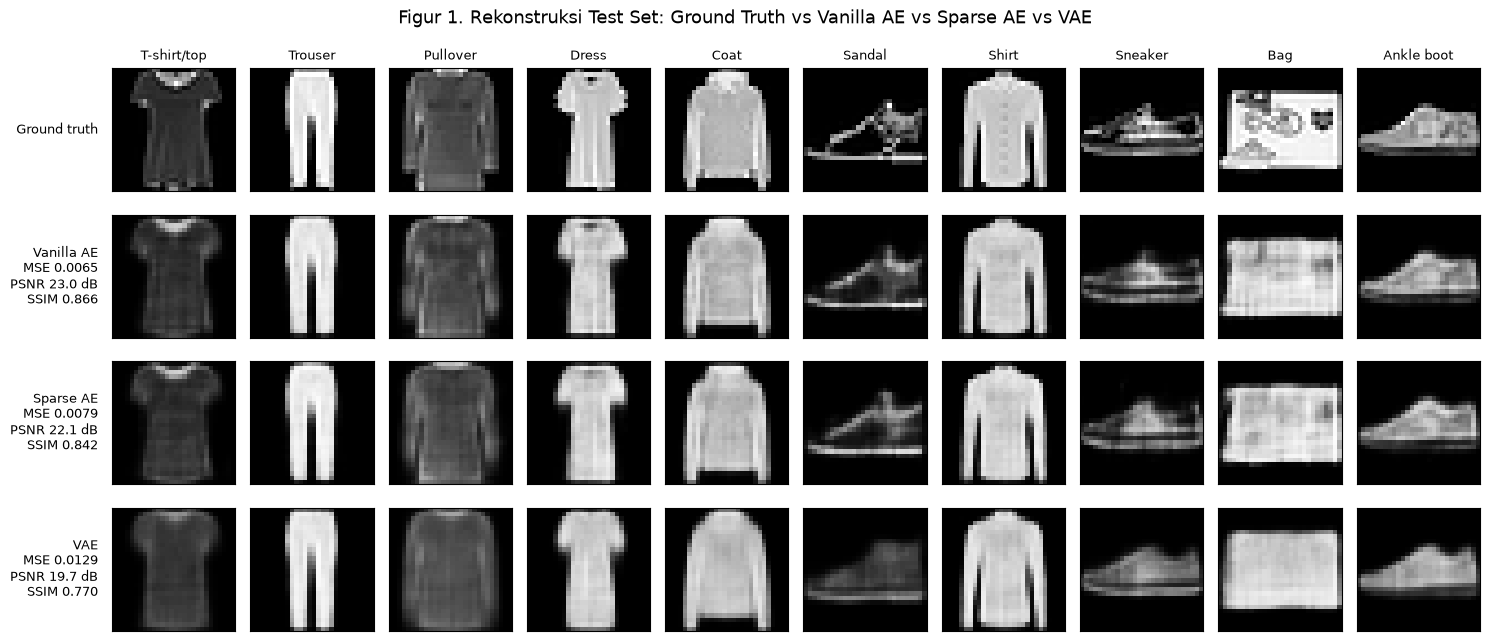

In [8]:
# Pilih satu gambar uji per kelas (indeks kedua dari tiap kelas)
idx = torch.stack([(Y_test == c).nonzero()[1, 0] for c in range(10)])
x10 = X_test[idx].to(DEVICE)
with torch.no_grad():
    # Baris: gambar asli + rekonstruksi tiap model
    rows_img = {"Ground truth": x10, **{k: f(x10) for k, f in recon_fns.items()}}
fig, axes = plt.subplots(4, 10, figsize=(15, 6.6))
for r, (name, imgs) in enumerate(rows_img.items()):
    for c in range(10):
        ax = axes[r, c]
        ax.imshow(imgs[c, 0].cpu(), cmap="gray", vmin=0, vmax=1)
        ax.set_xticks([]); ax.set_yticks([])
        if r == 0:
            ax.set_title(CLASSES[c], fontsize=9)   # nama kelas di atas kolom
        if c == 0:
            # Label baris berisi nama model + metriknya
            lab = name if name == "Ground truth" else (f"{name}\nMSE {recon[name]['mse']:.4f}\n"
                                                        f"PSNR {recon[name]['psnr']:.1f} dB\nSSIM {recon[name]['ssim']:.3f}")
            ax.set_ylabel(lab, fontsize=9, rotation=0, ha="right", va="center", labelpad=10)
fig.suptitle("Figur 1. Rekonstruksi Test Set: Ground Truth vs Vanilla AE vs Sparse AE vs VAE", fontsize=13)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "fig1_reconstruction_grid.png"), dpi=200, bbox_inches="tight")
plt.show()

## Figur 2 — Random generative sampling (4×4 per model)

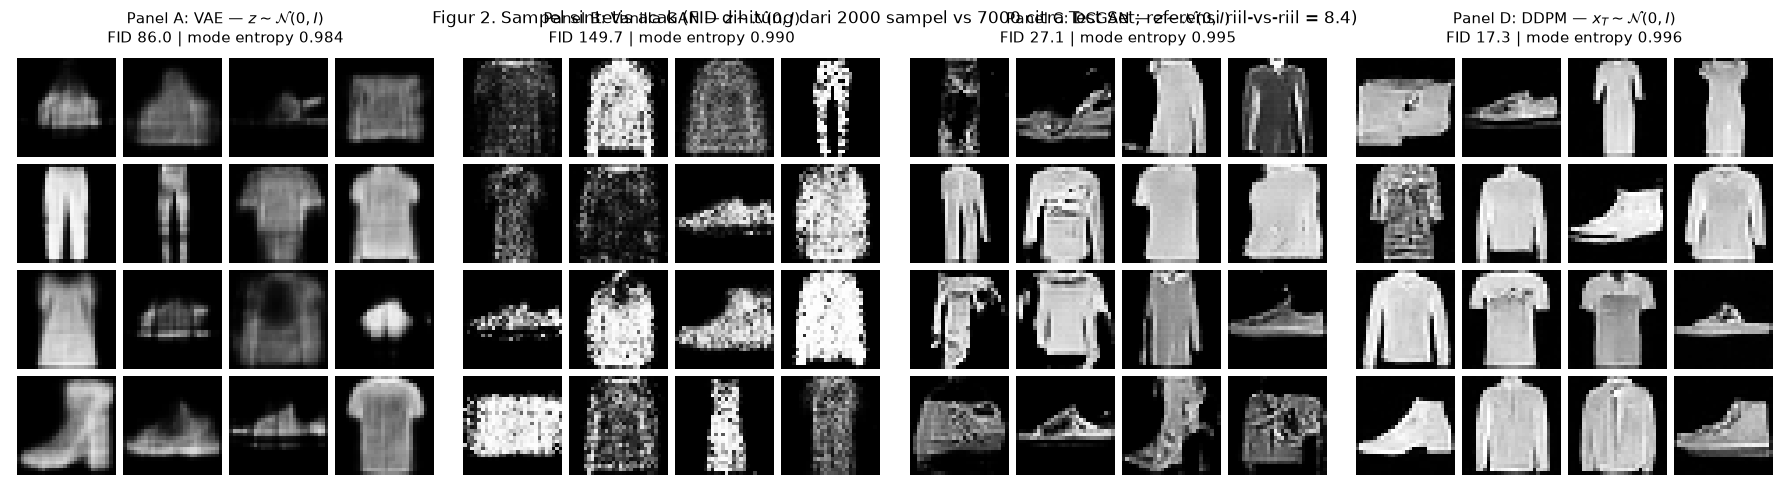

In [9]:
# 4 panel: 16 sampel acak dari masing-masing model generatif
fig, axes = plt.subplots(1, 4, figsize=(18, 5))
for ax, (lab, k) in zip(axes, (("A", "VAE"), ("B", "Vanilla GAN"), ("C", "DCGAN"), ("D", "DDPM"))):
    show_grid(samples[k][:16], nrow=4, ax=ax)
    # DDPM mulai dari x_T (noise seukuran gambar), lainnya dari vektor z
    prior = "$x_T\\sim\\mathcal{N}(0,I)$" if k == "DDPM" else "$z\\sim\\mathcal{N}(0,I)$"
    ax.set_title(f"Panel {lab}: {k} — {prior}\nFID {fid[k]:.1f} | mode entropy {coverage[k]['norm_entropy']:.3f}",
                 fontsize=11)
fig.suptitle(f"Figur 2. Sampel sintetis acak (FID dihitung dari {N_FID} sampel vs {len(X_test)} citra Test Set; "
             f"referensi riil-vs-riil = {fid['Real (Val Set) — reference']:.1f})", fontsize=12)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "fig2_random_sampling_grid.png"), dpi=200, bbox_inches="tight")
plt.show()

## Figur 4 — Linear latent space interpolation
$z(\alpha)=(1-\alpha)z_A+\alpha z_B$ dengan $\alpha\in\{0, 0.2, 0.4, 0.6, 0.8, 1\}$, dari kelas **Trouser** ke **Ankle boot**.
* AE, Sparse AE, VAE: $z_A,z_B$ = encoding dua citra uji (VAE memakai $\mu$).
* GAN/DCGAN (tanpa encoder): $z_A,z_B$ dipilih dari 4096 kandidat $z\sim\mathcal{N}(0,I)$ yang sampelnya diklasifikasikan
  sebagai kelas target dengan keyakinan tertinggi.

**Kuantifikasi latent voids**: untuk tiap titik $z(\alpha)$ dihitung jarak ke tetangga terdekat pada laten Train Set,
dinormalisasi dengan median jarak tetangga terdekat laten Test Set. Rasio > 1 berarti titik interpolasi berada di wilayah
yang tidak pernah ditempati data.

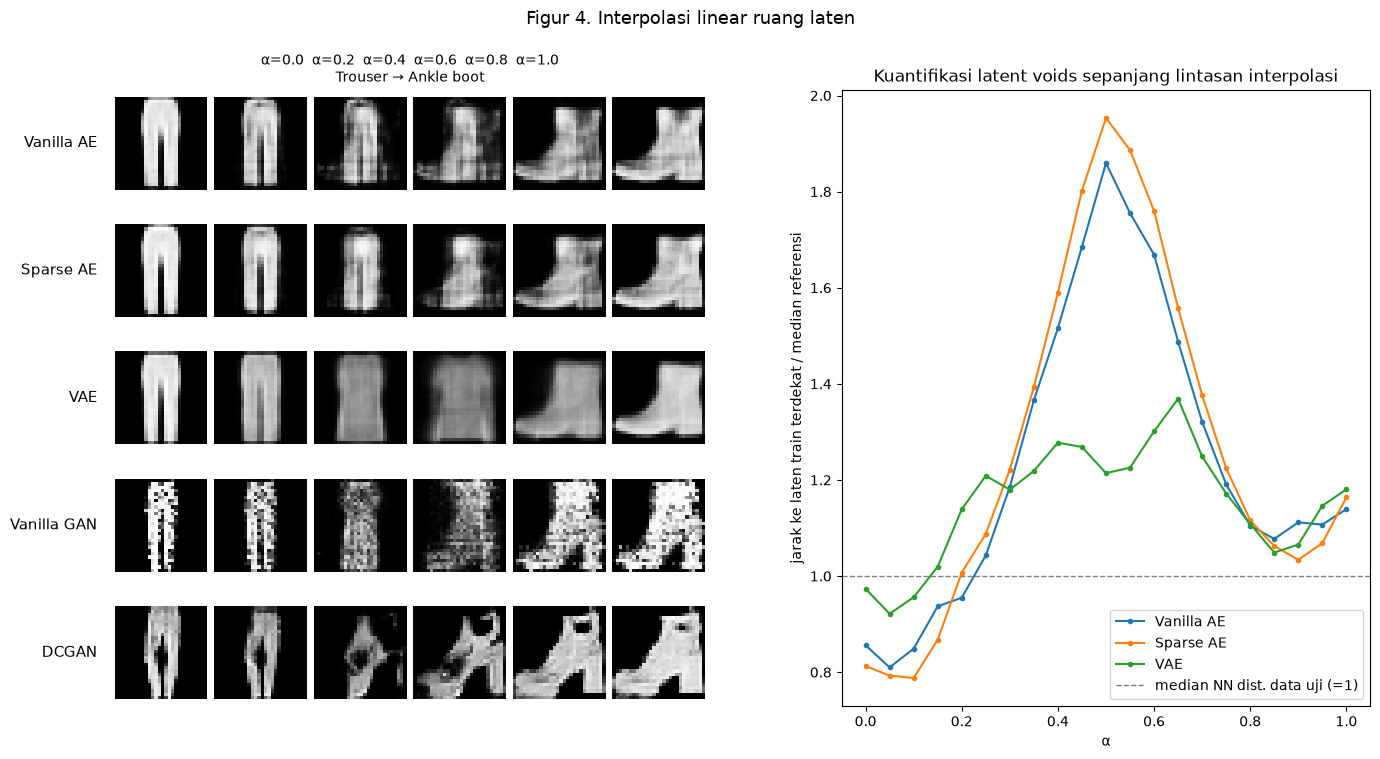

In [10]:
CA, CB = 1, 9                              # kelas awal (Trouser) dan akhir (Ankle boot)
ALPHAS = [0.0, 0.2, 0.4, 0.6, 0.8, 1.0]    # titik-titik interpolasi
with torch.no_grad():
    conf_test = clf(X_test.to(DEVICE)).softmax(1).cpu()
# Pilih gambar uji kelas CA dan CB yang paling yakin diklasifikasikan benar
iA = ((Y_test == CA).float() * conf_test[:, CA]).argmax()
iB = ((Y_test == CB).float() * conf_test[:, CB]).argmax()
xA, xB = X_test[iA:iA + 1].to(DEVICE), X_test[iB:iB + 1].to(DEVICE)


@torch.no_grad()
def pick_z(G, cls, n=4096):
    # GAN tidak punya encoder -> cari z (dari 4096 kandidat) yang hasilnya paling yakin berkelas `cls`
    set_seed(SEED)
    z = torch.randn(n, Z_DIM, device=DEVICE)
    p = clf(from_tanh_range(G(z))).softmax(1)[:, cls]
    return z[p.argmax()][None]


# (fungsi encode, fungsi decode) untuk keluarga autoencoder
encoders = {"Vanilla AE": (ae.encode, ae.decode), "Sparse AE": (sae.encode, sae.decode),
            "VAE": (lambda x: vae.encode(x)[0], vae.decode)}
interp_rows, endpoints = {}, {}
with torch.no_grad():
    for name, (enc, dec) in encoders.items():
        zA, zB = enc(xA), enc(xB)   # titik awal & akhir di ruang laten
        endpoints[name] = (zA, zB)
        # z(alpha) = (1 - alpha) * zA + alpha * zB, lalu decode
        interp_rows[name] = torch.cat([dec((1 - a) * zA + a * zB) for a in ALPHAS])
    for name, G in (("Vanilla GAN", G_gan), ("DCGAN", G_dc)):
        zA, zB = pick_z(G, CA), pick_z(G, CB)
        interp_rows[name] = torch.cat([from_tanh_range(G((1 - a) * zA + a * zB)) for a in ALPHAS])


@torch.no_grad()
def void_ratio(enc, zA, zB, steps=21):
    # Ukur apakah lintasan interpolasi melewati "daerah kosong" (latent voids) di ruang laten
    Ztr = torch.cat([enc(x.to(DEVICE)) for x, _ in train_loader])   # laten Train Set
    Zte = torch.cat([enc(x.to(DEVICE)) for x, _ in test_loader])    # laten Test Set
    # Referensi: median jarak tiap laten test ke tetangga terdekat di train
    ref = torch.cat([torch.cdist(Zte[i:i + 500], Ztr).min(1).values for i in range(0, len(Zte), 500)]).median()
    a = torch.linspace(0, 1, steps, device=DEVICE)[:, None]
    path = (1 - a) * zA + a * zB   # 21 titik sepanjang lintasan
    # Rasio > 1: titik interpolasi lebih jauh dari data dibanding biasanya (masuk daerah kosong)
    return a.squeeze(1).cpu(), (torch.cdist(path, Ztr).min(1).values / ref).cpu()


voids = {name: void_ratio(enc, *endpoints[name]) for name, (enc, _) in encoders.items()}
save_json({k: {"alpha": a.tolist(), "nn_distance_ratio": r.tolist()} for k, (a, r) in voids.items()},
          "interpolation_void_ratio.json")

# Layout: kiri = 5 baris interpolasi, kanan = grafik void ratio
fig = plt.figure(figsize=(17, 8))
gs = fig.add_gridspec(5, 2, width_ratios=[1.35, 1], wspace=0.12)
for r, (name, imgs) in enumerate(interp_rows.items()):
    ax = fig.add_subplot(gs[r, 0])
    show_grid(imgs, nrow=len(ALPHAS), ax=ax)
    ax.set_ylabel(name, rotation=0, ha="right", va="center", fontsize=11, labelpad=8)
    # Nyalakan axis agar label terlihat, tetapi sembunyikan tick & bingkai
    ax.axis("on"); ax.set_xticks([]); ax.set_yticks([])
    for s in ax.spines.values():
        s.set_visible(False)
    if r == 0:
        ax.set_title("  ".join([f"α={a:.1f}" for a in ALPHAS]) + f"\n{CLASSES[CA]} → {CLASSES[CB]}", fontsize=10)
ax = fig.add_subplot(gs[:, 1])
for name, (a, rr) in voids.items():
    ax.plot(a, rr, marker="o", ms=3, label=name)
ax.axhline(1.0, color="gray", ls="--", lw=1, label="median NN dist. data uji (=1)")   # garis referensi
ax.set_xlabel("α"); ax.set_ylabel("jarak ke laten train terdekat / median referensi")
ax.set_title("Kuantifikasi latent voids sepanjang lintasan interpolasi")
ax.legend()
fig.suptitle("Figur 4. Interpolasi linear ruang laten", fontsize=13)
plt.savefig(os.path.join(FIG_DIR, "fig4_latent_interpolation.png"), dpi=200, bbox_inches="tight")
plt.show()

## Figur 5 — Kurva training loss dan trajektori denoising DDPM

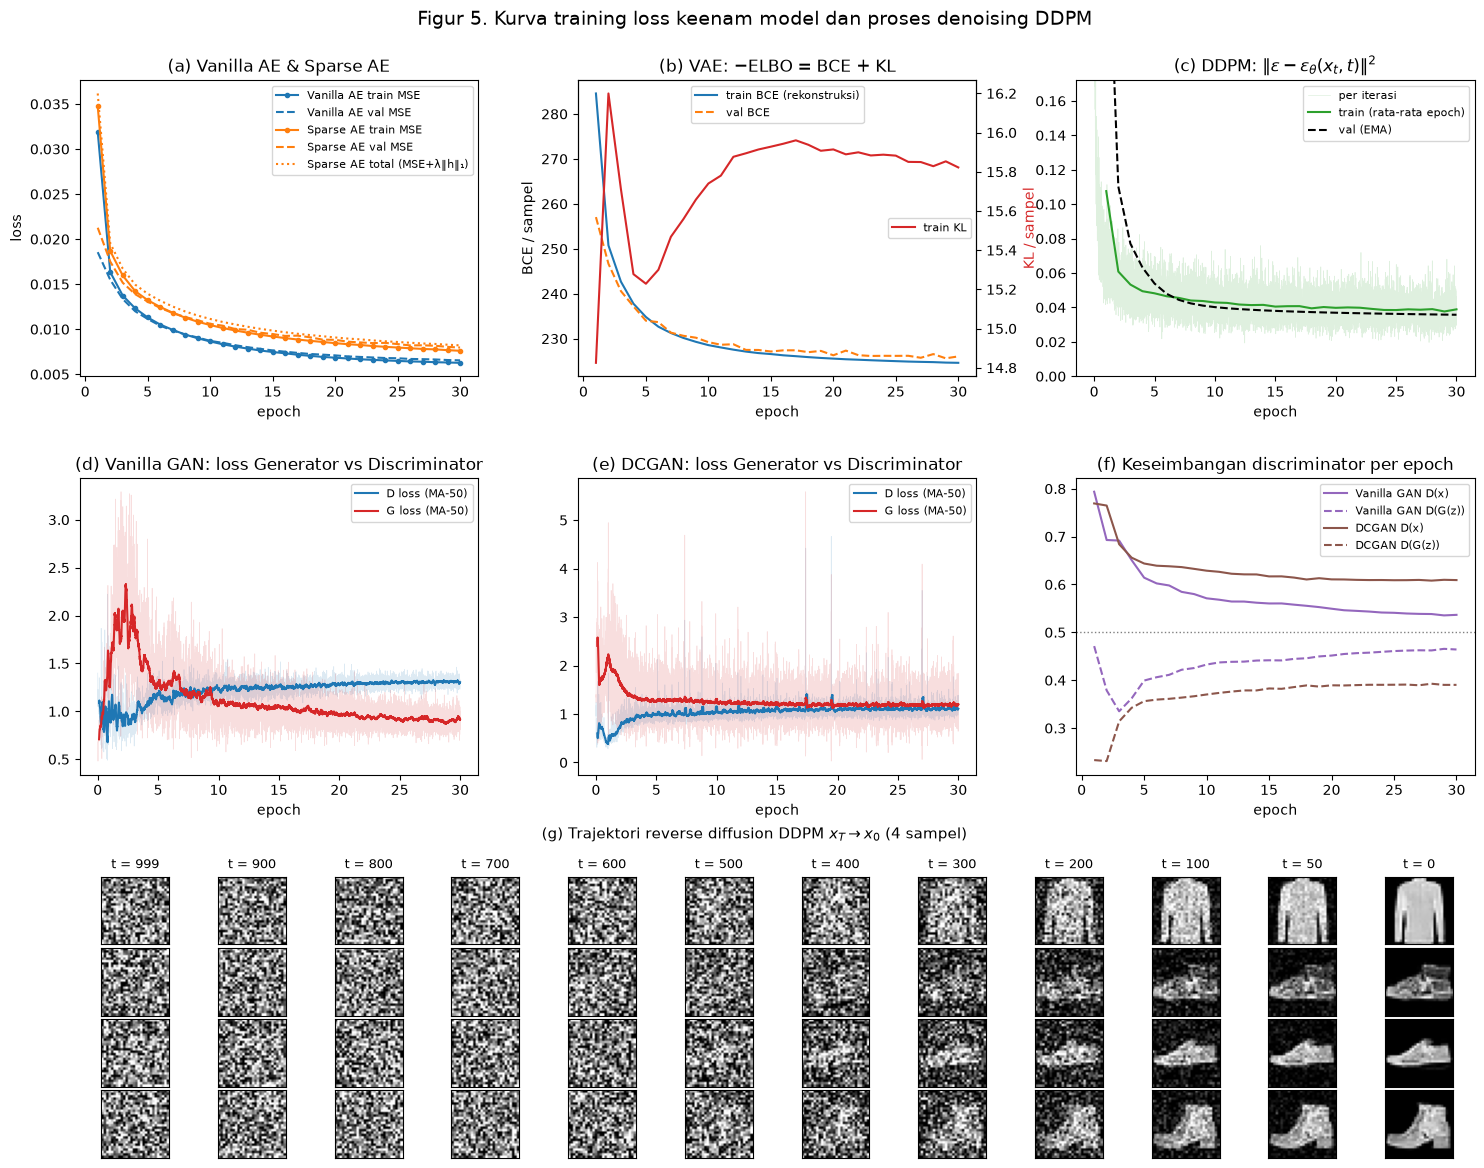

In [11]:
def smooth(y, k=50):
    # Moving average k titik untuk menghaluskan kurva loss per iterasi yang bergerigi
    y = np.asarray(y, dtype=float)
    return np.convolve(y, np.ones(k) / k, mode="valid") if len(y) > k else y


traj = torch.load(os.path.join(RESULTS_DIR, "ddpm_trajectory.pt"))   # trajektori dari notebook 03
# Layout 3x3: baris 1-2 = kurva loss, baris 3 = trajektori DDPM
fig = plt.figure(figsize=(18, 14))
gs = fig.add_gridspec(3, 3, height_ratios=[1, 1, 0.95], hspace=0.35, wspace=0.25)
ep = lambda h, k: np.arange(1, len(h[k]) + 1)   # sumbu x: nomor epoch 1..N

# (a) Kurva MSE Vanilla AE & Sparse AE (train = garis penuh, val = putus-putus)
ax = fig.add_subplot(gs[0, 0])
for name, c in (("Vanilla AE", "C0"), ("Sparse AE", "C1")):
    ax.plot(ep(hist[name], "train_recon_mse"), hist[name]["train_recon_mse"], c=c, marker=".", label=f"{name} train MSE")
    ax.plot(ep(hist[name], "val_recon_mse"), hist[name]["val_recon_mse"], c=c, ls="--", label=f"{name} val MSE")
ax.plot(ep(hist["Sparse AE"], "train_loss"), hist["Sparse AE"]["train_loss"], c="C1", ls=":",
        label="Sparse AE total (MSE+λ‖h‖₁)")
ax.set_title("(a) Vanilla AE & Sparse AE"); ax.set_xlabel("epoch"); ax.set_ylabel("loss"); ax.legend(fontsize=8)

# (b) VAE: BCE di sumbu kiri, KL di sumbu kanan (skalanya berbeda jauh)
ax = fig.add_subplot(gs[0, 1])
h = hist["VAE"]
ax.plot(ep(h, "train_bce"), h["train_bce"], label="train BCE (rekonstruksi)")
ax.plot(ep(h, "val_bce"), h["val_bce"], ls="--", label="val BCE")
ax.set_xlabel("epoch"); ax.set_ylabel("BCE / sampel")
ax2 = ax.twinx()   # sumbu y kedua
ax2.plot(ep(h, "train_kl"), h["train_kl"], c="C3", label="train KL"); ax2.set_ylabel("KL / sampel", color="C3")
ax.set_title("(b) VAE: −ELBO = BCE + KL"); ax.legend(loc="upper center", fontsize=8); ax2.legend(loc="center right", fontsize=8)

# (c) DDPM: loss per iterasi (transparan), rata-rata epoch, dan val EMA
ax = fig.add_subplot(gs[0, 2])
h = hist["DDPM"]
ax.plot(np.arange(len(h["iter_loss"])) / (len(h["iter_loss"]) / len(h["train_loss"])), h["iter_loss"],
        alpha=0.15, c="C2", lw=0.5, label="per iterasi")
ax.plot(ep(h, "train_loss"), h["train_loss"], c="C2", label="train (rata-rata epoch)")
ax.plot(ep(h, "val_loss"), h["val_loss"], c="k", ls="--", label="val (EMA)")
ax.set_ylim(0, max(h["train_loss"][0] * 1.6, 0.1))
ax.set_title("(c) DDPM: $\\|\\epsilon-\\epsilon_\\theta(x_t,t)\\|^2$"); ax.set_xlabel("epoch"); ax.legend(fontsize=8)

# (d) & (e) GAN: loss D vs G per iterasi + versi dihaluskan
for j, name in enumerate(("Vanilla GAN", "DCGAN")):
    ax = fig.add_subplot(gs[1, j])
    h = hist[name]
    it = np.arange(len(h["iter_d_loss"])) / (len(h["iter_d_loss"]) / len(h["d_loss"]))   # iterasi -> satuan epoch
    ax.plot(it, h["iter_d_loss"], c="C0", alpha=0.15, lw=0.5)
    ax.plot(it, h["iter_g_loss"], c="C3", alpha=0.15, lw=0.5)
    ax.plot(it[49:], smooth(h["iter_d_loss"]), c="C0", label="D loss (MA-50)")
    ax.plot(it[49:], smooth(h["iter_g_loss"]), c="C3", label="G loss (MA-50)")
    ax.set_title(f"({'de'[j]}) {name}: loss Generator vs Discriminator"); ax.set_xlabel("epoch"); ax.legend(fontsize=8)

# (f) Rata-rata D(x) dan D(G(z)); idealnya keduanya mendekati 0.5 (D tidak bisa membedakan)
ax = fig.add_subplot(gs[1, 2])
for name, c in (("Vanilla GAN", "C4"), ("DCGAN", "C5")):
    h = hist[name]
    ax.plot(ep(h, "d_real"), h["d_real"], c=c, label=f"{name} D(x)")
    ax.plot(ep(h, "d_fake"), h["d_fake"], c=c, ls="--", label=f"{name} D(G(z))")
ax.axhline(0.5, c="gray", lw=1, ls=":")
ax.set_title("(f) Keseimbangan discriminator per epoch"); ax.set_xlabel("epoch"); ax.legend(fontsize=8)

# (g) Trajektori denoising DDPM: 4 sampel x 12 timestep
sub = gs[2, :].subgridspec(4, len(traj["t"]), wspace=0.05, hspace=0.05)
for j, t in enumerate(traj["t"]):
    for i in range(4):
        ax = fig.add_subplot(sub[i, j])
        ax.imshow(traj["traj"][t][i, 0], cmap="gray", vmin=0, vmax=1)
        ax.set_xticks([]); ax.set_yticks([])
        if i == 0:
            ax.set_title(f"t = {t}", fontsize=9)
fig.text(0.5, 0.338, "(g) Trajektori reverse diffusion DDPM $x_T \\rightarrow x_0$ (4 sampel)", ha="center", fontsize=11)
fig.suptitle("Figur 5. Kurva training loss keenam model dan proses denoising DDPM", fontsize=14, y=0.93)
plt.savefig(os.path.join(FIG_DIR, "fig5_training_curves_ddpm_trajectory.png"), dpi=200, bbox_inches="tight")
plt.show()

## Figur suplementer — vanishing gradient dan mode coverage

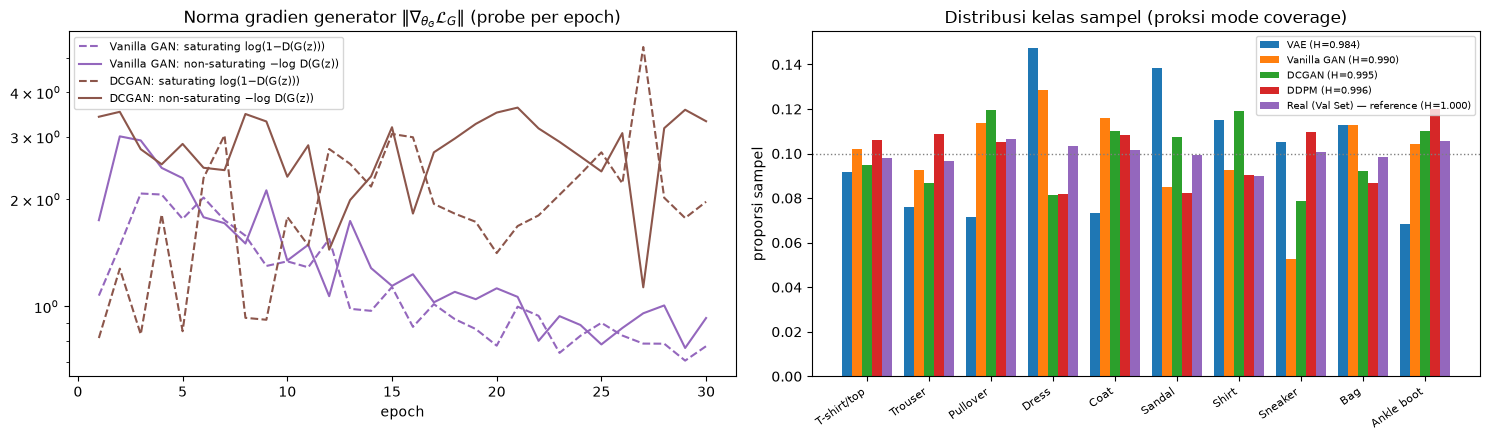

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))

# Panel kiri: norma gradien generator untuk loss saturating vs non-saturating (skala log)
# Garis saturating yang jauh lebih rendah = bukti vanishing gradient
ax = axes[0]
for name, c in (("Vanilla GAN", "C4"), ("DCGAN", "C5")):
    h = hist[name]
    ax.semilogy(ep(h, "probe_grad_saturating"), h["probe_grad_saturating"], c=c, ls="--",
                label=f"{name}: saturating log(1−D(G(z)))")
    ax.semilogy(ep(h, "probe_grad_non_saturating"), h["probe_grad_non_saturating"], c=c,
                label=f"{name}: non-saturating −log D(G(z))")
ax.set_title("Norma gradien generator $\\|\\nabla_{\\theta_G}\\mathcal{L}_G\\|$ (probe per epoch)")
ax.set_xlabel("epoch"); ax.legend(fontsize=8)

# Panel kanan: proporsi sampel per kelas untuk tiap model (bar chart berdampingan)
ax = axes[1]
keys = ["VAE", "Vanilla GAN", "DCGAN", "DDPM", "Real (Val Set) — reference"]
w = 0.16   # lebar tiap bar
for i, k in enumerate(keys):
    hcl = np.array(coverage[k]["class_hist"]) / N_FID
    ax.bar(np.arange(10) + (i - 2) * w, hcl, width=w, label=f"{k} (H={coverage[k]['norm_entropy']:.3f})")
ax.set_xticks(range(10)); ax.set_xticklabels(CLASSES, rotation=35, ha="right", fontsize=8)
ax.axhline(0.1, c="gray", ls=":", lw=1)   # 10% = sebaran ideal (merata)
ax.set_ylabel("proporsi sampel"); ax.set_title("Distribusi kelas sampel (proksi mode coverage)"); ax.legend(fontsize=7)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "figS2_gradient_probe_mode_coverage.png"), dpi=200, bbox_inches="tight")
plt.show()